# 🏦 Bank Customer Churn Analysis & Prediction

---

## 📌 Project Overview
**Customer churn** happens when a customer stops doing business with a company. For a bank, every customer who leaves means lost revenue, and acquiring a new customer usually costs far more than retaining an existing one. If the bank can *predict* which customers are likely to leave, it can step in early with targeted retention offers.

This notebook analyses a dataset of 10,000 bank customers and builds a machine learning model that predicts whether a customer will leave the bank.

## 🎯 Objectives
1. Load and validate the data (missing values, duplicates, formatting).
2. Explore the data to understand **who churns and why** (EDA).
3. Build a **Random Forest classification pipeline** to predict churn.
4. Evaluate the model and use it to predict churn for a new customer.
5. Save the trained pipeline so it can be reused without retraining.

## 🗂️ Table of Contents
1. Importing Libraries
2. Loading the Dataset
3. Data Preprocessing & Quality Checks
4. Exploratory Data Analysis (EDA)
5. Feature Selection
6. Model Building & Evaluation
7. Predicting for a New Customer
8. Saving the Model
9. Conclusion & Next Steps

## 📖 Data Dictionary
| Column | Description |
|---|---|
| `RowNumber` | Row index (identifier, no predictive value) |
| `CustomerId` | Unique customer ID (identifier, no predictive value) |
| `Surname` | Customer surname (identifier, no predictive value) |
| `CreditScore` | Customer's credit score |
| `Geography` | Country of residence (France, Spain, Germany) |
| `Gender` | Male / Female |
| `Age` | Customer age in years |
| `Tenure` | Number of years the customer has been with the bank |
| `Balance` | Account balance |
| `NumOfProducts` | Number of bank products the customer holds |
| `HasCrCard` | 1 if the customer has a credit card, else 0 |
| `IsActiveMember` | 1 if the customer is an active member, else 0 |
| `EstimatedSalary` | Estimated annual salary |
| **`Exited`** | **Target variable:** 1 = customer left the bank, 0 = customer stayed |

---
# 1. Importing Libraries

We start by importing the Python libraries used throughout the notebook:
- **NumPy / Pandas**: numerical computation and data manipulation.
- **Matplotlib / Seaborn**: data visualisation.

Machine learning libraries (scikit-learn, joblib) are imported later, right where they are needed.

In [4]:
# Importing the libraries:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

---
# 2. Loading the Dataset

The data is read from a CSV file (`Churn_Modelling.csv`) into a Pandas DataFrame. `df.info()` gives a quick overview of the dataset: number of rows, column names, data types and non-null counts.

> **Note:** the path `/content/...` is the Google Colab upload location. If you run this notebook locally, change it to the path where the CSV is stored.

**What we learn:** the dataset has **10,000 rows and 14 columns** (11 numeric, 3 text), and every column shows 10,000 non-null values.

In [5]:
# Importing the Dataset:
df= pd.read_csv('Churn_Modelling.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


---
# 3. Data Preprocessing & Quality Checks

Before analysing anything, we verify the data is clean and reliable. Poor data quality leads to misleading insights and weak models. We check for:
1. Missing values
2. Duplicate records
3. Inconsistent categories or formatting errors

## 3.1 Previewing the Data
A first look at the top 5 rows to understand what each record looks like.

In [6]:
# Display the first 5 rows of the dataset
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 3.2 Checking for Missing Values
`isnull().sum()` counts the empty cells in each column.

**Result:** every column has **0 missing values**, so no imputation or row removal is needed.

In [7]:
# Checking for null values:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

## 3.3 Checking for Duplicate Records
Duplicate rows can bias both the analysis and the model, so we count them.

**Result:** **0 duplicates** found.

In [8]:
# Checking for duplicate values:
df.duplicated().sum()

np.int64(0)

## 3.4 Identifying Categorical Columns
We separate out the text (`object`) columns, since they need different treatment from numeric ones, both when inspecting the data and later when encoding it for the model.

**Result:** `Surname`, `Geography` and `Gender` are the categorical columns.

In [9]:
categorical_columns = df.select_dtypes(include=['object']).columns
categorical_columns

C:\Users\Surya\AppData\Local\Temp\ipykernel_3020\2864691023.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns


Index(['Surname', 'Geography', 'Gender'], dtype='str')

## 3.5 Inspecting Unique Values of Categorical Columns
We print the unique values in each categorical column to catch typos, inconsistent spellings or unexpected categories.

**Result:**
- `Geography` has 3 clean categories: France, Spain, Germany.
- `Gender` has 2 clean categories: Female, Male.
- `Surname` is a high-cardinality identifier (thousands of unique names) and will be dropped before modelling.

In [10]:
for col in categorical_columns:
    print(df[col].unique())
    print("--"*50)

<ArrowStringArray>
[  'Hargrave',       'Hill',       'Onio',       'Boni',   'Mitchell',
        'Chu',   'Bartlett',     'Obinna',         'He',         'H?',
 ...
 'MacPherson',      'Parks',      'Edith',     'Lajoie',     'Torode',
    'Salinas',  'Cleveland',  'Kashiwagi',   'Aldridge',   'Burbidge']
Length: 2932, dtype: str
----------------------------------------------------------------------------------------------------
<ArrowStringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str
----------------------------------------------------------------------------------------------------
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
----------------------------------------------------------------------------------------------------


## 3.6 Data Quality Summary
| Check | Result |
|---|---|
| Data type errors | ✅ None |
| Missing values | ✅ None |
| Duplicate records | ✅ None |
| Formatting / category errors | ✅ None |

The dataset is clean, so we can move on to exploratory analysis.

---
# 4. Exploratory Data Analysis (EDA)

EDA helps us understand the structure of the data, the shape of each feature, and which factors appear related to customers leaving. We go through it in four steps:
1. Distributions of numerical features
2. Distribution of the target variable
3. Relationship of key features with churn
4. Outliers and correlations

## 4.1 Column Overview
Listing the columns again for reference before we start plotting.

In [11]:
# List all column names
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

## 4.2 Distributions of Numerical Features
Histograms show how values are spread: whether they are symmetric or skewed, and whether there are unusual values.

### 4.2.1 Credit Score
The credit scores form a roughly **bell-shaped (approximately normal)** distribution, with most customers scoring between about 500 and 800. Very low scores (below 400) are rare.

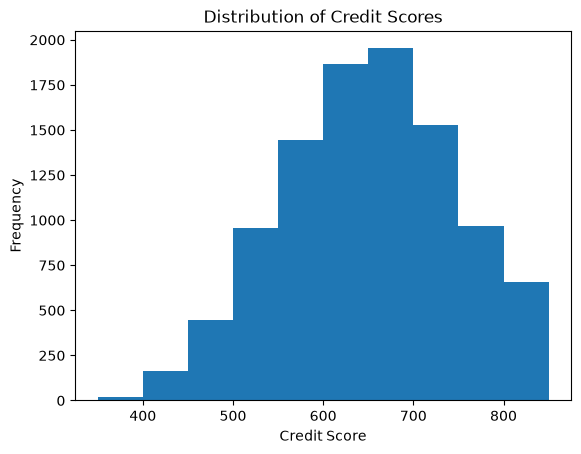

In [12]:
# Histogram of CreditScore
df['CreditScore'].plot(kind='hist')
plt.xlabel('Credit Score')
plt.ylabel('Frequency')
plt.title('Distribution of Credit Scores')
plt.show()

### 4.2.2 Age
The age distribution is **right-skewed**: most customers are in their 30s and 40s, and there is a long tail of older customers (up to about 90 years).

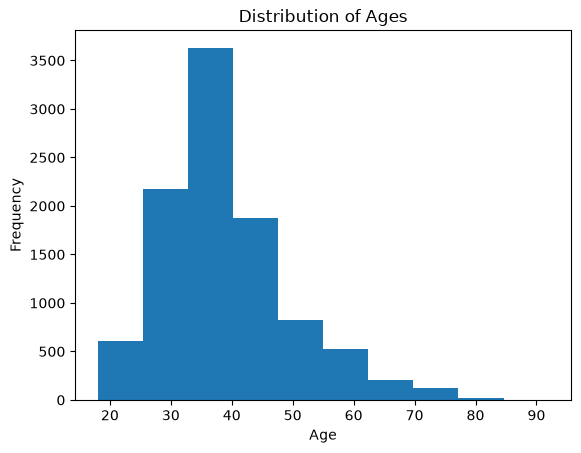

In [13]:
# Histogram of Age (before outlier treatment)
df['Age'].plot(kind='hist')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Ages')
plt.show()

### 4.2.3 Age: Outlier Check (Box Plot)
A box plot is the quickest way to spot outliers. Here, many points lie above the upper whisker (roughly age 62), which means there are a number of unusually old customers compared with the rest of the data.

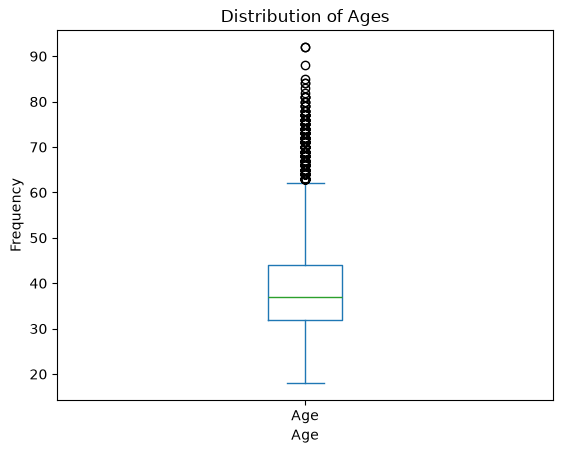

In [14]:
# Box plot of Age to detect outliers
df['Age'].plot(kind='box')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Ages')
plt.show()

### 4.2.4 Treating Age Outliers
Customers older than 65 are rare and can distort the analysis and the model, so we keep only customers aged **65 or below**. This removes **264 rows** (10,000 → 9,736).

> The 65 cut-off is a judgement call (a common retirement-age threshold) rather than a strict statistical rule such as 1.5×IQR.

In [15]:
# Keep only customers aged 65 or below (removes age outliers)
df= df[df['Age']<=65]

### 4.2.5 Age After Outlier Removal
The long right tail is gone. The distribution is now more compact, with most customers between 25 and 45.

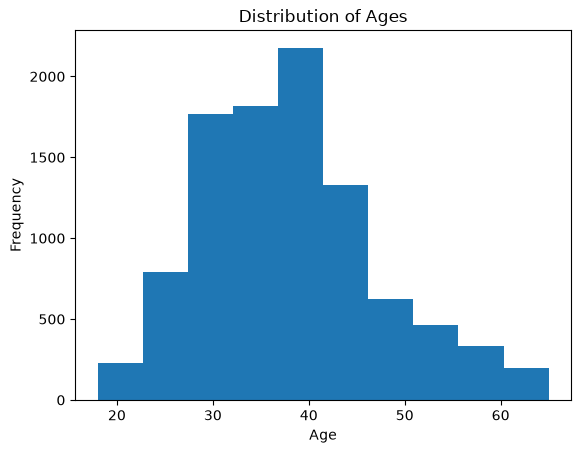

In [16]:
# Histogram of Age after removing outliers
df['Age'].plot(kind='hist')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Ages')
plt.show()

### 4.2.6 Tenure
Tenure (years with the bank) is spread **fairly evenly between 1 and 9 years**. The first bar (0 years, new customers) is shorter because that bin holds only tenure 0, while the last bar (9-10 years) is taller because the final histogram bin combines tenure 9 and 10. This is a binning effect rather than a real pattern.

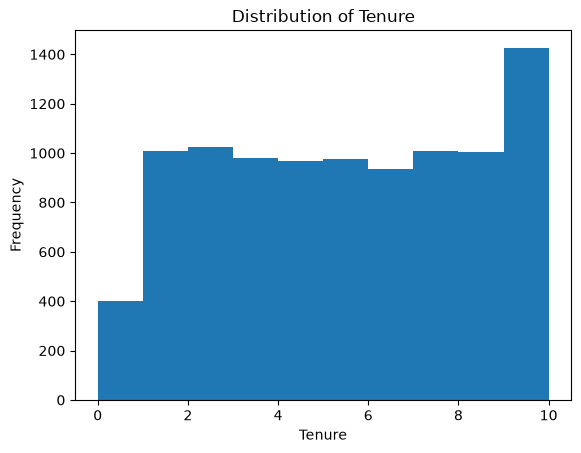

In [17]:
# Histogram of Tenure
df['Tenure'].plot(kind='hist')
plt.xlabel('Tenure')
plt.ylabel('Frequency')
plt.title('Distribution of Tenure')
plt.show()

### 4.2.7 Estimated Salary
Salary is **uniformly distributed** from near 0 to about 200,000, with no skew and no obvious outliers.

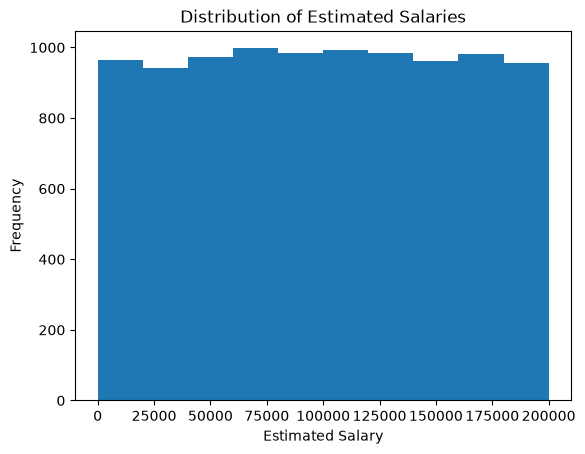

In [18]:
# Histogram of EstimatedSalary
df['EstimatedSalary'].plot(kind='hist')
plt.xlabel('Estimated Salary')
plt.ylabel('Frequency')
plt.title('Distribution of Estimated Salaries')
plt.show()

## 4.3 Distribution of the Target Variable (`Exited`)
Before modelling, we need to know how balanced the two classes are:
- `0` = customer **stayed**
- `1` = customer **left (churned)**

**Observation:** the dataset is **imbalanced**. Roughly 79% of customers stayed and only about 21% left. A model could reach high accuracy just by predicting "stayed" for everyone, so we must look at precision and recall for the churn class, not accuracy alone.

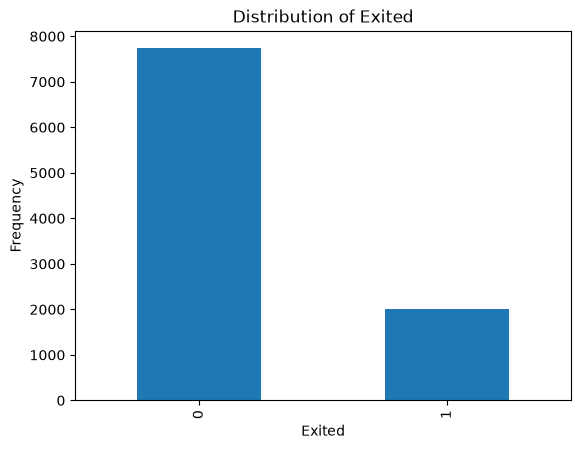

In [19]:
# Distribution chart target variable:
df['Exited'].value_counts().plot(kind='bar')
plt.xlabel('Exited')
plt.ylabel('Frequency')
plt.title('Distribution of Exited')
plt.show()

## 4.4 Relationship Between Features and Churn
Next we compare churn across key features using stacked bar charts. Each bar is split into customers who stayed (blue, `0`) and customers who left (orange, `1`).

### 4.4.1 Activity Status vs. Churn

**Observation:** among **inactive members** (`0`) the proportion of customers who exit is clearly higher than among active members (`1`), roughly 26% versus 14%. Customer engagement is therefore an important churn signal.

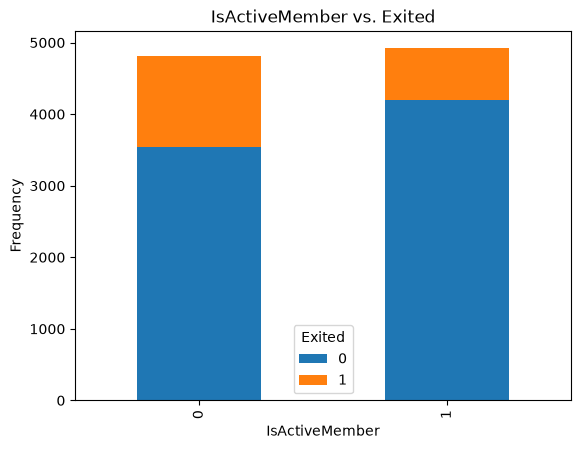

In [20]:
# IsActiveMember vs. Exited
df.groupby('IsActiveMember')['Exited'].value_counts().unstack().plot(kind='bar', stacked=True)
plt.xlabel('IsActiveMember')
plt.ylabel('Frequency')
plt.title('IsActiveMember vs. Exited')
plt.show()

### 4.4.2 Age vs. Churn
Here we look at how churn varies with age, one bar per age.

**Observation:** the orange share is small for customers in their 20s and early 30s, and **grows steadily from the late 30s onwards**. In the late 40s and 50s a large portion (often a third or more) of customers leave. Age is therefore a strong churn indicator.

> Note: the first line (`plt.figure(figsize=(20, 10))`) creates an extra empty figure, which is why an empty `Figure size 2000x1000` line appears in the output. Pandas draws the actual chart on a new figure. To use a larger size, pass `figsize=(20, 10)` inside `.plot()` instead.

<Figure size 2000x1000 with 0 Axes>

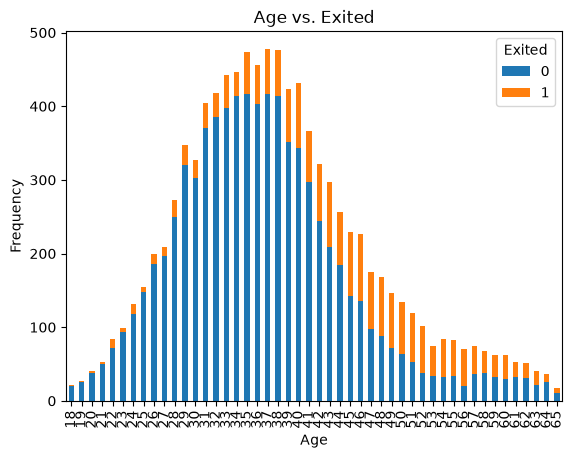

In [21]:
# Stacked bar chart: churn counts at each age
# Age overlapping the Exited categories
plt.figure(figsize=(20, 10))
df.groupby('Age')['Exited'].value_counts().unstack().plot(kind='bar', stacked=True)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age vs. Exited')
plt.show()

### 4.4.3 Geography vs. Churn
Comparing churn across the three countries.

**Observation:**
- France has the most customers, with a relatively low churn share.
- **Germany** has far fewer customers than France but a much **higher churn rate** (roughly a third of its customers leave).
- Spain has a similar customer count to Germany but a **lower churn rate**, similar to France.

This suggests the German market may need special attention.

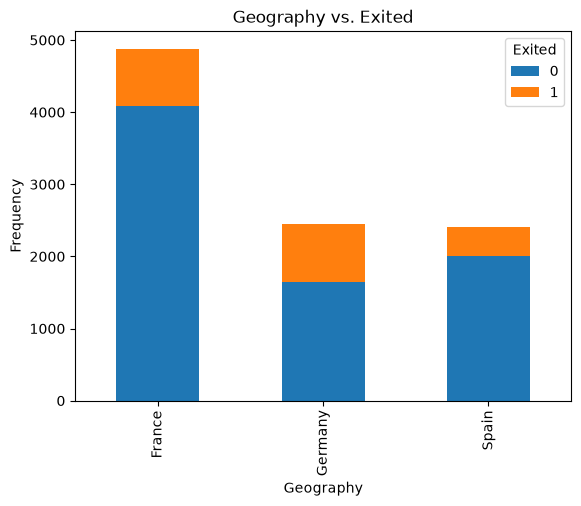

In [22]:
# Stacked bar chart: churn by country
#Geography vs. Exited
df.groupby('Geography')['Exited'].value_counts().unstack().plot(kind='bar', stacked=True)
plt.xlabel('Geography')
plt.ylabel('Frequency')
plt.title('Geography vs. Exited')
plt.show()

## 4.5 Summary Statistics & Outlier Check
`df.describe()` summarises count, mean, standard deviation, min, quartiles and max for each numeric column. It helps us detect odd ranges.

**Key points:**
- After filtering, **9,736 customers** remain; the age range is 18-65 (mean about 38).
- **About 20.6% of customers churned** (mean of `Exited` ≈ 0.206).
- `Balance` has a minimum and 25th percentile of 0, which means **a large share of customers hold a zero balance**.
- `NumOfProducts` ranges from 1 to 4; `CreditScore` ranges from 350 to 850. Both are within valid ranges.
- `RowNumber` and `CustomerId` are just identifiers, so their statistics are not meaningful.

In [23]:
# Summary statistics of all numeric columns
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,9736.000000,9.736000e+03,9736.000000,9736.000000,9736.000000,9736.000000,9736.000000,9736.000000,9736.000000,9736.000000,9736.000000
mean,4997.895542,1.569093e+07,650.159614,38.045193,5.010682,76625.916492,1.530403,0.705423,0.505238,100094.215689,0.205629
std,2888.024354,7.186521e+04,96.630511,9.124962,2.891443,62384.133946,0.581958,0.455876,0.499998,57506.628865,0.404181
min,1.000000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,2490.750000,1.562850e+07,583.000000,32.000000,2.750000,0.000000,1.000000,0.000000,0.000000,51014.837500,0.000000
50%,5001.000000,1.569098e+07,651.000000,37.000000,5.000000,97350.825000,1.000000,1.000000,1.000000,100185.240000,0.000000
75%,7497.250000,1.575308e+07,717.000000,43.000000,7.000000,127724.497500,2.000000,1.000000,1.000000,149388.247500,0.000000
max,10000.000000,1.581569e+07,850.000000,65.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,199992.480000,1.000000


## 4.6 Correlation Analysis
A correlation heatmap shows the linear relationship between every pair of numeric variables (from −1 to +1). We focus on the **`Exited` row/column**.

**Key findings:**
| Feature | Correlation with `Exited` | Interpretation |
|---|---|---|
| `Age` | **+0.35** | Strongest relationship: older customers are more likely to leave |
| `IsActiveMember` | **−0.15** | Active members are less likely to leave |
| `Balance` | **+0.12** | Customers with higher balances are slightly more likely to leave |
| `NumOfProducts` | −0.05 | Weak linear relationship |
| `CreditScore`, `Tenure`, `HasCrCard`, `EstimatedSalary` | close to 0 | Little linear relationship with churn |

Also, `Balance` and `NumOfProducts` are moderately negatively correlated (−0.30). The ID columns (`RowNumber`, `CustomerId`) show no correlation with anything, as expected.

> Correlation only captures *linear* relationships, so features with a low correlation (such as `NumOfProducts`) can still matter to a non-linear model like Random Forest.

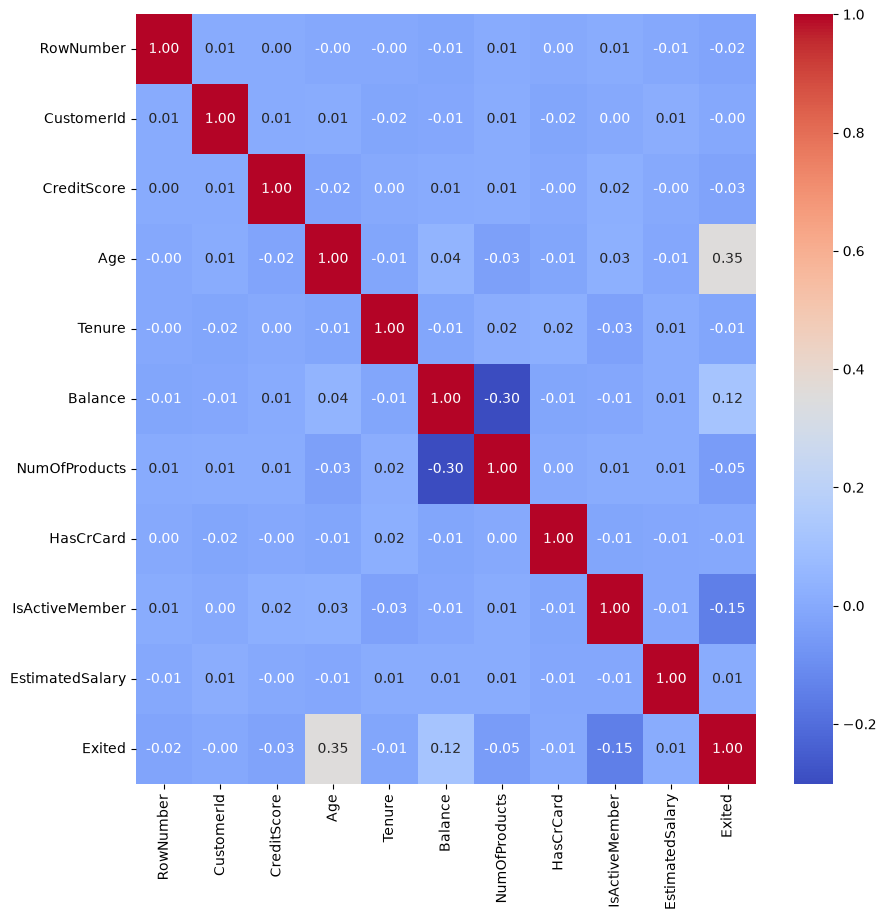

In [24]:
# Correlation heatmap of numeric features
matrix = df.corr(numeric_only=True)
plt.figure(figsize=(10, 10))
sns.heatmap(matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

## 4.7 EDA Key Takeaways
- ⚠️ The target is **imbalanced**: only about 1 in 5 customers churned.
- 👴 **Age** is the strongest churn driver; churn rises noticeably in older age groups.
- 😴 **Inactive members** churn much more than active ones.
- 🇩🇪 **German customers** churn at a much higher rate than customers in France or Spain.
- 💰 Customers with higher balances show a slightly higher churn tendency.

---
# 5. Feature Selection

We split the data into:
- **`X` (features):** the input variables used to make predictions.
- **`Y` (target):** the `Exited` column we want to predict.

We drop `RowNumber`, `CustomerId` and `Surname` because they are only identifiers. They carry no real information about churn, and keeping them could cause the model to memorise individual customers rather than learn general patterns.

In [25]:
# Features (X): drop identifier columns and the target
# Target (Y): the Exited column
X= df.drop(['RowNumber','CustomerId','Surname','Exited'], axis=1)
Y= df['Exited']

---
# 6. Model Building & Evaluation

We build a single scikit-learn **Pipeline** that handles preprocessing and modelling together. This keeps the workflow clean, avoids data leakage, and lets us save and reuse the whole thing as one object.

## 6.1 Creating Working Copies of the Data
We make copies of `X` and `Y` so the originals stay untouched while we work on the model.

In [26]:
x= X.copy()
y= Y.copy()

## 6.2 Previewing the Feature Set
A quick check that the feature table has the expected columns (no identifiers, no target).

In [27]:
# Preview the features
x.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary
0,619,France,Female,42,2,0.00,1,1,1,101348.88
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58
2,502,France,Female,42,8,159660.80,3,1,0,113931.57
3,699,France,Female,39,1,0.00,2,0,0,93826.63
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10


## 6.3 Separating Numerical and Categorical Features
Different column types need different preprocessing, so we pick them out by data type:
- **Numerical features** (integers and floats) → will be **scaled**.
- **Categorical features** (text) → will be **one-hot encoded**.

In [28]:
# Split feature names by data type
# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns

C:\Users\Surya\AppData\Local\Temp\ipykernel_3020\608121919.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


## 6.4 Building, Training and Evaluating the Pipeline

This cell does the following:

1. **Preprocessing (`ColumnTransformer`)**
   - `StandardScaler` standardises numerical features (mean 0, standard deviation 1).
   - `OneHotEncoder` converts categorical columns (`Geography`, `Gender`) into 0/1 columns. `handle_unknown="ignore"` prevents errors if an unseen category appears at prediction time.
2. **Model (`RandomForestClassifier`)**
   - An ensemble of 100 decision trees.
   - `class_weight="balanced"` gives more weight to the minority class (churners) to partly compensate for the imbalance found in the EDA.
   - `random_state=42` makes results reproducible.
3. **Train/test split:** 80% training and 20% testing. `stratify=y` keeps the same churn ratio in both sets.
4. **Fit → Predict → Evaluate** on the unseen test set.

### 📊 Understanding the Results
| Metric | Class 0 (Stayed) | Class 1 (Churned) |
|---|---|---|
| Precision | 0.87 | 0.82 |
| Recall | 0.98 | **0.41** |
| F1-score | 0.92 | 0.55 |

- **Accuracy = 86.0%.** This looks good, but is partly inflated because most customers (about 79%) stay.
- **Precision for churners (0.82):** when the model flags someone as likely to leave, it is right about 82% of the time.
- **Recall for churners (0.41):** the model catches only about **41% of the customers who actually leave**; it misses the other 59%. For a retention use case, this is the weakest point.
- The model is very good at identifying customers who will *stay* (recall 0.98) but conservative about flagging churners.

> 💡 Ways to improve churn recall are listed in the *Next Steps* section at the end.

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Categorical Transformer
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)

# Numerical Transformer
numerical_transformer = StandardScaler()

# Combine Transformers
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Create Single ML Pipeline
pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Fit Pipeline
pipeline.fit(X_train, y_train)

# Prediction
y_pred = pipeline.predict(X_test)

# Model Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8429158110882957

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.90      1547
           1       0.63      0.56      0.59       401

    accuracy                           0.84      1948
   macro avg       0.76      0.74      0.75      1948
weighted avg       0.84      0.84      0.84      1948



---
# 7. Predicting for a New Customer

The trained pipeline accepts raw customer data (without any manual scaling or encoding) and returns a prediction. Here we create a single customer profile with the same columns as the training features and ask the model whether they are likely to leave.

> **Note:** the sample values are taken from the first row of the dataset, so this is only a demonstration of how to use the pipeline, not an independent test of the model's accuracy.

In [30]:
# Create a sample customer (same columns as the training features)
new_customer = pd.DataFrame([{
    "CreditScore": 619,
    "Geography": "France",
    "Gender": "Female",
    "Age": 42,
    "Tenure": 2,
    "Balance": 0.0,
    "NumOfProducts": 1,
    "HasCrCard": 1,
    "IsActiveMember": 1,
    "EstimatedSalary": 101348.88
}])

prediction = pipeline.predict(new_customer)

print("\nNew Customer Prediction:")

if prediction[0] == 1:
    print("Customer is likely to EXIT.")
else:
    print("Customer is likely to STAY.")


New Customer Prediction:
Customer is likely to EXIT.


---
# 8. Saving the Model

The complete pipeline (preprocessing + model) is saved to a `.pkl` file with `joblib`. It can be loaded later (for example in a web app or API) using `joblib.load('churn_prediction_model.pkl')`, without retraining.

> **Note:** the printed message below says "Model Loaded", but the cell actually **saves** the model. You may want to change it to "Model Saved Successfully.".

In [31]:
import joblib
joblib.dump(pipeline, 'churn_prediction_model.pkl')
print("Model Loaded Completely.")

Model Loaded Completely.


---
# 9. Conclusion & Next Steps

## ✅ Summary of What We Did
1. Loaded and validated a 10,000-customer dataset; it had no missing values or duplicates.
2. Removed age outliers (customers older than 65), leaving 9,736 customers.
3. Explored the data and found that **age, inactivity and geography (Germany)** are linked to higher churn.
4. Built a Random Forest pipeline (scaling + one-hot encoding + classifier) that reaches about **86% accuracy**.
5. Demonstrated predicting for a new customer and saved the model for reuse.

## ⚠️ Limitations
- **Low recall for churners (41%)**: the model misses more than half of the customers who leave.
- The dataset is **imbalanced** (about 21% churn), so accuracy alone is not a reliable measure of success.
- The model was evaluated on a single train/test split with default hyperparameters.

## 🚀 Next Steps
- **Handle imbalance better:** try SMOTE, under/over-sampling, or tune the decision threshold to raise recall.
- **Tune hyperparameters** (`GridSearchCV` / `RandomizedSearchCV`) for the Random Forest.
- **Compare other models:** Logistic Regression, XGBoost, LightGBM, Gradient Boosting.
- **Use better metrics:** ROC-AUC, precision-recall curve and confusion matrix, not just accuracy.
- **Cross-validation** for a more reliable performance estimate.
- **Feature importance / SHAP** to explain which features drive each prediction.
- **Feature engineering**, for example balance-to-salary ratio or age groups.
- **Business action:** use the predictions to target at-risk customers (older, inactive, German customers) with retention offers.